In [1]:
# FINAURA
# Initial Model Training Experiments
# NIFTY 50 - Future 5-Day Volatility Prediction

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error

In [3]:
input_path = "../data/processed/nifty50_processed.csv"

df = pd.read_csv(input_path)

df["date"] = pd.to_datetime(df["date"])

print("Dataset shape:", df.shape)

Dataset shape: (2331, 24)


In [4]:
df.head()


,date,adj_close,close,high,low,open,volume,daily_return,log_return,intraday_return,...,ma_50,volatility_5d,volatility_10d,volatility_20d,momentum_5d,momentum_20d,drawdown,volume_ma_20,volume_ratio,target_5d_volatility
0,2017-03-15,9084.799805,9084.799805,9106.549805,9075.500000,9086.849609,240600,-0.000242,-0.000242,-0.000226,...,8663.496953,0.124675,0.103294,0.088733,0.015413,0.031772,-0.000242,216350.0,1.112087,0.101812
1,2017-03-16,9153.700195,9153.700195,9158.450195,9128.549805,9129.650391,208600,0.007584,0.007556,0.002634,...,8682.980957,0.116484,0.103474,0.090419,0.025705,0.041104,0.000000,217365.0,0.959676,0.094497
2,2017-03-17,9160.049805,9160.049805,9218.400391,9147.599609,9207.799805,286700,0.000694,0.000693,-0.005186,...,8702.336953,0.115504,0.095527,0.083039,0.026106,0.049899,0.000000,220895.0,1.297902,0.097657
3,2017-03-20,9126.849609,9126.849609,9167.599609,9116.299805,9166.950195,332100,-0.003624,-0.003631,-0.004374,...,8721.063945,0.129543,0.100035,0.084519,0.021523,0.039741,-0.003624,228270.0,1.454856,0.105422
4,2017-03-21,9121.500000,9121.500000,9147.750000,9087.200195,9133.950195,247700,-0.000586,-0.000586,-0.001363,...,8738.017949,0.065588,0.097208,0.084188,0.003797,0.033984,-0.004208,225740.0,1.097280,0.120044


In [5]:
print("Target column:")
print("target_5d_volatility" in df.columns)

print("\nTarget statistics:")
print(df["target_5d_volatility"].describe())

Target column:
True

Target statistics:
count    2331.000000
mean        0.129183
std         0.103511
min         0.016931
25%         0.074815
50%         0.105178
75%         0.147847
max         1.335954
Name: target_5d_volatility, dtype: float64


In [6]:
candidate_features = [
    "daily_return",
    "log_return",
    "intraday_return",
    "price_range",
    "ma_5",
    "ma_10",
    "ma_20",
    "ma_50",
    "volatility_5",
    "volatility_10",
    "volatility_20",
    "momentum_5",
    "momentum_20",
    "drawdown"
]

features = [
    col for col in candidate_features
    if col in df.columns
]

print("Selected features:")
print(features)

Selected features:
['daily_return', 'log_return', 'intraday_return', 'price_range', 'ma_5', 'ma_10', 'ma_20', 'ma_50', 'drawdown']


In [7]:
model_df = df[
    features + ["target_5d_volatility"]
].copy()

model_df = model_df.dropna().reset_index(drop=True)

print("Model dataset shape:", model_df.shape)

Model dataset shape: (2331, 10)


In [8]:
X = model_df[features]
y = model_df["target_5d_volatility"]

split_index = int(len(model_df) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 1864
Testing samples: 467


In [9]:
date_df = df.loc[
    model_df.index,
    ["date"]
].reset_index(drop=True)

train_end_date = date_df.iloc[split_index - 1]["date"]
test_start_date = date_df.iloc[split_index]["date"]

print("Training ends:", train_end_date)
print("Testing starts:", test_start_date)

Training ends: 2024-10-07 00:00:00
Testing starts: 2024-10-08 00:00:00


In [10]:
baseline_prediction = np.full(
    len(y_test),
    y_train.mean()
)

print("Baseline prediction:", y_train.mean())

Baseline prediction: 0.13271570125962637


In [11]:
baseline_mae = mean_absolute_error(
    y_test,
    baseline_prediction
)

baseline_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        baseline_prediction
    )
)

print("Baseline MAE:", baseline_mae)
print("Baseline RMSE:", baseline_rmse)

Baseline MAE: 0.05139684918717991
Baseline RMSE: 0.06640602897044826


In [12]:
linear_model = LinearRegression()

linear_model.fit(
    X_train,
    y_train
)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [13]:
linear_predictions = linear_model.predict(
    X_test
)

print(
    "First 10 predictions:"
)

print(
    linear_predictions[:10]
)

First 10 predictions:
[0.17673556 0.19534102 0.16935463 0.15579229 0.14019029 0.15507765
 0.14800912 0.18103415 0.16914128 0.18036272]


In [14]:
linear_mae = mean_absolute_error(
    y_test,
    linear_predictions
)

linear_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        linear_predictions
    )
)

print("Linear Regression MAE:", linear_mae)
print("Linear Regression RMSE:", linear_rmse)

Linear Regression MAE: 0.05891789911605781
Linear Regression RMSE: 0.07367182340111054


In [15]:
rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(
    X_train,
    y_train
)

,n_estimators,200
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [16]:
rf_predictions = rf_model.predict(
    X_test
)

print(
    "First 10 predictions:"
)

print(
    rf_predictions[:10]
)

First 10 predictions:
[0.14895258 0.15854674 0.12573967 0.11895362 0.12319704 0.13502155
 0.13054483 0.14821551 0.13978047 0.15933948]


In [17]:
rf_mae = mean_absolute_error(
    y_test,
    rf_predictions
)

rf_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        rf_predictions
    )
)

print("Random Forest MAE:", rf_mae)
print("Random Forest RMSE:", rf_rmse)

Random Forest MAE: 0.054881775231384405
Random Forest RMSE: 0.067316519407186


In [18]:
results = pd.DataFrame({
    "Model": [
        "Baseline",
        "Linear Regression",
        "Random Forest"
    ],
    "MAE": [
        baseline_mae,
        linear_mae,
        rf_mae
    ],
    "RMSE": [
        baseline_rmse,
        linear_rmse,
        rf_rmse
    ]
})

results

,Model,MAE,RMSE
0,Baseline,0.051397,0.066406
1,Linear Regression,0.058918,0.073672
2,Random Forest,0.054882,0.067317


In [19]:
results.sort_values(
    "MAE"
).reset_index(drop=True)

,Model,MAE,RMSE
0,Baseline,0.051397,0.066406
1,Random Forest,0.054882,0.067317
2,Linear Regression,0.058918,0.073672


In [20]:
comparison_df = pd.DataFrame({
    "Actual": y_test.values,
    "Baseline": baseline_prediction,
    "Linear_Regression": linear_predictions,
    "Random_Forest": rf_predictions
})

comparison_df.head(10)

,Actual,Baseline,Linear_Regression,Random_Forest
0,0.058261,0.132716,0.176736,0.148953
1,0.063865,0.132716,0.195341,0.158547
2,0.088283,0.132716,0.169355,0.125740
3,0.098994,0.132716,0.155792,0.118954
4,0.073928,0.132716,0.140190,0.123197
5,0.101400,0.132716,0.155078,0.135022
6,0.103863,0.132716,0.148009,0.130545
7,0.096393,0.132716,0.181034,0.148216
8,0.079638,0.132716,0.169141,0.139780
9,0.117916,0.132716,0.180363,0.159339


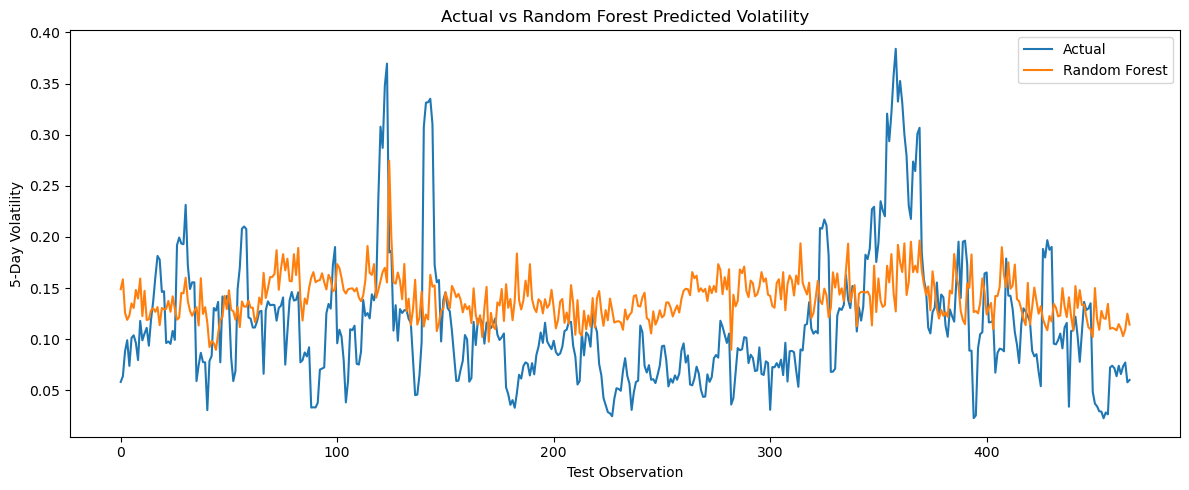

In [21]:
plt.figure(figsize=(12, 5))

plt.plot(
    comparison_df["Actual"].values,
    label="Actual"
)

plt.plot(
    comparison_df["Random_Forest"].values,
    label="Random Forest"
)

plt.xlabel("Test Observation")
plt.ylabel("5-Day Volatility")
plt.title("Actual vs Random Forest Predicted Volatility")
plt.legend()

plt.tight_layout()
plt.show()

In [22]:
feature_importance = pd.DataFrame({
    "Feature": features,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=False
).reset_index(drop=True)

feature_importance

,Feature,Importance
0,drawdown,0.292148
1,price_range,0.279569
2,ma_50,0.136623
3,ma_20,0.073378
4,ma_5,0.057765
5,ma_10,0.049866
6,intraday_return,0.043718
7,log_return,0.034370
8,daily_return,0.032562


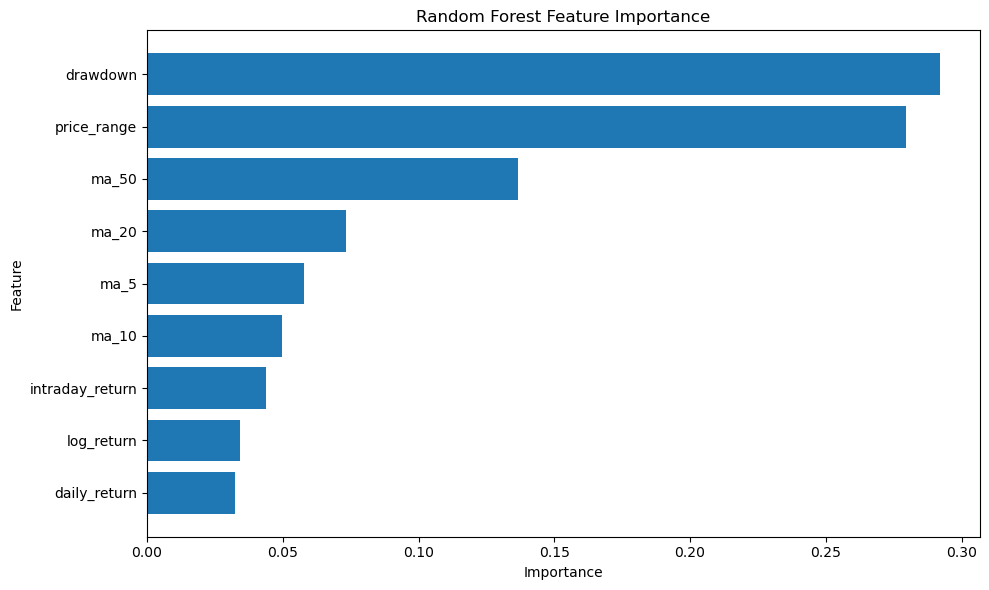

In [23]:
plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [24]:
best_model = results.loc[
    results["MAE"].idxmin(),
    "Model"
]

best_mae = results["MAE"].min()

print("INITIAL MODEL EXPERIMENT SUMMARY")
print("================================")

print("Target: Next 5-Day Realized Volatility")

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nResults:")
print(results)

print("\nBest initial model based on MAE:")
print(best_model)

print("\nBest MAE:")
print(best_mae)

INITIAL MODEL EXPERIMENT SUMMARY
Target: Next 5-Day Realized Volatility
Training samples: 1864
Testing samples: 467

Results:
               Model       MAE      RMSE
0           Baseline  0.051397  0.066406
1  Linear Regression  0.058918  0.073672
2      Random Forest  0.054882  0.067317

Best initial model based on MAE:
Baseline

Best MAE:
0.05139684918717991


In [25]:
results.to_csv(
    "../data/processed/initial_model_results.csv",
    index=False
)

print("Model experiment results saved successfully.")

Model experiment results saved successfully.


In [26]:
feature_importance.to_csv(
    "../data/processed/random_forest_feature_importance.csv",
    index=False
)

print("Feature importance saved successfully.")

Feature importance saved successfully.
